# CR03 - Calibration and fairness audit (German Credit)

Goal: (1) check whether the CR01 scorecard PDs are calibrated and whether Platt or isotonic
calibration helps, and (2) audit approval and error rates by Sex and age band at a cutoff.

Split: the CR01 holdout (30%, stratified, seed 42) is the test set. The 70% training part is
split again into a model-fit part (70%) and a calibration part (30%). The calibrator never sees
test data.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
from sklearn.metrics import brier_score_loss

from calibration_fairness.audit import (
    IsotonicCalibrator,
    PlattCalibrator,
    age_band,
    disparity,
    group_audit,
    split_fit_calibration,
)
from credit_core.metrics import expected_calibration_error, gini
from credit_core.plots import plot_reliability
from scorecard_woe.pipeline import FEATURES, GermanSplit, fit_scorecard, load_split

FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

## 1. Fit, calibrate, test

In [2]:
split = load_split()
X_fit, X_cal, y_fit, y_cal = split_fit_calibration(split.X_train, split.y_train)
fit_split = GermanSplit(X_fit, split.X_test, y_fit, split.y_test)

sc, C = fit_scorecard(fit_split)
print(f"Tuned C = {C}, fit n = {len(X_fit)}, calibration n = {len(X_cal)}, test n = {len(split.X_test)}")

# Raw probability of good (y=1 means good) from the scorecard.
p_cal_raw = sc.predict_good(X_cal[FEATURES])
p_test_raw = sc.predict_good(split.X_test[FEATURES])

platt = PlattCalibrator().fit(p_cal_raw, y_cal)
iso = IsotonicCalibrator().fit(p_cal_raw, y_cal)

variants = {
    "raw": p_test_raw,
    "platt": platt.predict(p_test_raw),
    "isotonic": iso.predict(p_test_raw),
}

rows = []
for name, p in variants.items():
    rows.append(
        {
            "variant": name,
            "brier": brier_score_loss(split.y_test, p),
            "ece": expected_calibration_error(split.y_test, p, n_bins=10),
            "mean_pred_good": float(np.mean(p)),
            "observed_good": float(split.y_test.mean()),
            "gini": gini(split.y_test, p),
        }
    )
calib_table = pd.DataFrame(rows).set_index("variant").round(4)
calib_table

Tuned C = 1.0, fit n = 490, calibration n = 210, test n = 300


,brier,ece,mean_pred_good,observed_good,gini
variant,,,,,
raw,0.1806,0.0249,0.7142,0.7,0.4719
platt,0.1820,0.0625,0.7115,0.7,0.4719
isotonic,0.1885,0.0816,0.7060,0.7,0.4523


Gini is rank-based, so a monotone map (Platt) leaves it unchanged. Isotonic changes it because
its steps create ties. On this test set the raw scorecard is already the best calibrated:
both calibrators were fit on only 210 calibration rows and add noise rather than correction.
Calibration is not applied to the audit's ranking below; the raw PD is used.

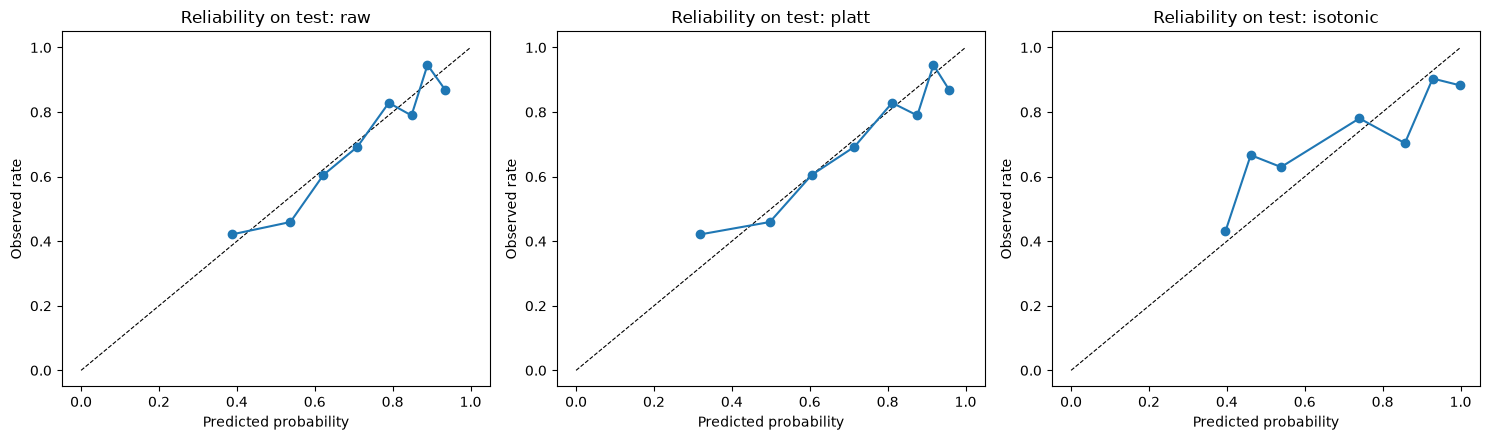

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, p) in zip(axes, variants.items()):
    plot_reliability(split.y_test, p, n_bins=8, ax=ax)
    ax.set_title(f"Reliability on test: {name}")
fig.tight_layout()
fig.savefig(FIG / "cr03_reliability.png", dpi=120)
plt.show()

## 2. Fairness audit by Sex and age band

Approve when the PD is at or below a cutoff that approves the 70% of test applicants with the
lowest PD. We use the raw scorecard PD, which was the best calibrated on the test set (section 1).

In [4]:
p_good = variants["raw"]
pd_test = 1.0 - p_good
cutoff = float(np.quantile(pd_test, 0.70))
print(f"PD cutoff (approve 70% of test): {cutoff:.4f}")

groups = split.X_test["Sex"].astype(str)
audit_sex = group_audit(split.y_test.values, p_good, groups, cutoff)
audit_sex

PD cutoff (approve 70% of test): 0.3874


,n,bad_rate,approval_rate,bad_rate_approved,bad_flagged_rate
group,,,,,
female,96,0.343750,0.708333,0.264706,0.454545
male,204,0.279412,0.696078,0.169014,0.578947


In [5]:
bands = age_band(split.X_test["Age"])
audit_age = group_audit(split.y_test.values, p_good, bands, cutoff)
audit_age

,n,bad_rate,approval_rate,bad_rate_approved,bad_flagged_rate
group,,,,,
25-39,160,0.268750,0.725000,0.198276,0.465116
40+,93,0.279570,0.741935,0.159420,0.576923
<25,47,0.446809,0.531915,0.320000,0.619048


In [6]:
disp = pd.DataFrame(
    [
        {"attribute": "Sex", **disparity(audit_sex, "approval_rate")},
        {"attribute": "Age band", **disparity(audit_age, "approval_rate")},
        {"attribute": "Sex", **disparity(audit_sex, "bad_rate_approved")},
        {"attribute": "Age band", **disparity(audit_age, "bad_rate_approved")},
    ]
)
disp

,attribute,column,min_max_ratio,four_fifths_flag
0,Sex,approval_rate,0.982699,False
1,Age band,approval_rate,0.716929,True
2,Sex,bad_rate_approved,0.638498,True
3,Age band,bad_rate_approved,0.498188,True


`bad_rate_approved` is the bad rate among approved applicants. A large gap means the cutoff
lets more bad applicants through in one group, which is a calibration/error-rate disparity.

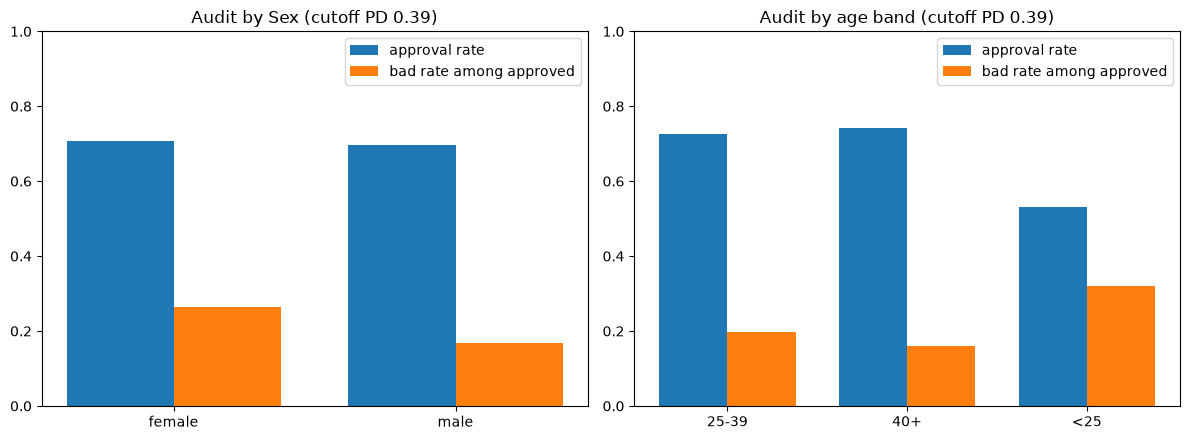

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, audit, title in [(axes[0], audit_sex, "by Sex"), (axes[1], audit_age, "by age band")]:
    x = np.arange(len(audit))
    w = 0.38
    ax.bar(x - w / 2, audit["approval_rate"], w, label="approval rate")
    ax.bar(x + w / 2, audit["bad_rate_approved"], w, label="bad rate among approved")
    ax.set_xticks(x)
    ax.set_xticklabels(audit.index)
    ax.set_ylim(0, 1)
    ax.set_title(f"Audit {title} (cutoff PD {cutoff:.2f})")
    ax.legend()
fig.tight_layout()
fig.savefig(FIG / "cr03_fairness_audit.png", dpi=120)
plt.show()

## 3. Proxy check: is Housing associated with Sex?

Sex is not in the model, but a feature can still carry it. Housing is a categorical feature in
the scorecard, so we test its association with Sex (chi-squared and Cramér's V) on the full
German data.

In [8]:
full = pd.concat([split.X_train, split.X_test])
ct = pd.crosstab(full["Housing"], full["Sex"])
chi2, p_val, dof, _ = chi2_contingency(ct)
n = ct.values.sum()
cramers_v = float(np.sqrt(chi2 / (n * (min(ct.shape) - 1))))
proxy = pd.DataFrame([{"feature": "Housing", "chi2": chi2, "p_value": p_val, "cramers_v": cramers_v}])
proxy.round(4)

,feature,chi2,p_value,cramers_v
0,Housing,53.955,0.0,0.2323


In [9]:
ct

Sex,female,male
Housing,,
free,19,89
own,196,517
rent,95,84


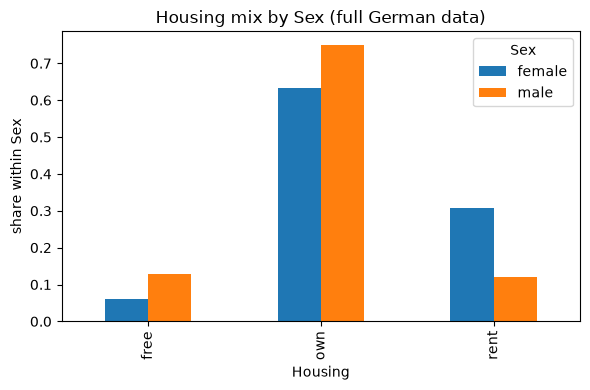

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
ct.div(ct.sum(axis=0), axis=1).plot(kind="bar", ax=ax)
ax.set_ylabel("share within Sex")
ax.set_title("Housing mix by Sex (full German data)")
fig.tight_layout()
fig.savefig(FIG / "cr03_proxy_housing.png", dpi=120)
plt.show()

## 4. Summary

- Calibration: the raw scorecard has the lowest ECE and the lowest Brier on the test set. Platt
  and isotonic, fit on 210 rows, do not help here.
- Fairness: approval rates by Sex are similar (ratio about 0.98). Approval by age band is not
  (under 25 approved at 53%, against about 73% to 74% for the other bands). Bad rate among
  approved applicants is higher for women (26%, against 17% for men) and for under-25s (32%).
  Both bad-rate ratios fail the four-fifths screen. Age is a model input, so its approval gap is
  expected from the score. The Sex gap in bad rate among approved is a warning to investigate.
  With 300 test rows and 96 women, these ratios have wide uncertainty.
- Proxy: Housing is strongly associated with Sex (Cramér's V about 0.23, p < 0.001). Housing
  is a scorecard feature, so Sex can enter the model indirectly. This must be stated in the
  README and checked in a larger dataset.

In [11]:
calib_table

,brier,ece,mean_pred_good,observed_good,gini
variant,,,,,
raw,0.1806,0.0249,0.7142,0.7,0.4719
platt,0.1820,0.0625,0.7115,0.7,0.4719
isotonic,0.1885,0.0816,0.7060,0.7,0.4523
